In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

from statsmodels.tsa.stattools import adfuller, coint

## Cointegration

In [2]:
# Load data
gs3m = pd.read_csv('data/GS3M.csv', index_col='observation_date', parse_dates=True)
gs10 = pd.read_csv('data/GS10.csv', index_col='observation_date', parse_dates=True)
df = gs10.join(gs3m, how='inner')
df['spread'] = df['GS10'] - df['GS3M']

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


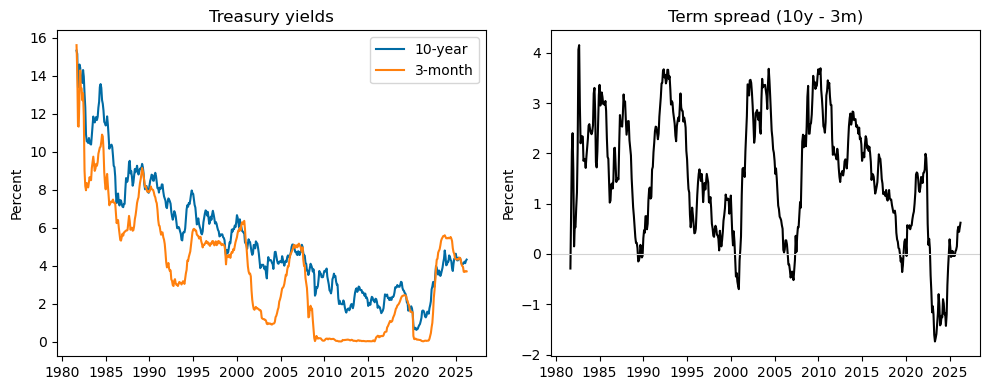

In [3]:
# Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(df.index, df['GS10'], label='10-year')
axes[0].plot(df.index, df['GS3M'], label='3-month')
axes[0].set_title('Treasury yields')
axes[0].set_ylabel('Percent')
axes[0].legend()

axes[1].plot(df.index, df['spread'], color='black')
axes[1].axhline(0, color='lightgrey', linewidth=0.8)
axes[1].set_title('Term spread (10y - 3m)')
axes[1].set_ylabel('Percent')

plt.tight_layout()
fig.savefig('output/treasury_yields.eps')
plt.show()

In [4]:
# ADF unit root test for each series (constant + trend)
for s in ['GS3M', 'GS10']:
    stat, pval, nlags, *_ = adfuller(df[s], regression='ct', autolag='AIC')
    print(f'{s}: ADF stat = {stat:.3f}, p-value = {pval:.3f}, lags = {nlags}')

# Test known cointegrating relationship (no trend)
stat, pval, nlags, *_ = adfuller(df['spread'], regression='c', autolag='AIC')
print(f'Spread: ADF stat = {stat:.3f}, p-value = {pval:.3f}, lags = {nlags}')

GS3M: ADF stat = -2.856, p-value = 0.177, lags = 10
GS10: ADF stat = -2.971, p-value = 0.140, lags = 3
Spread: ADF stat = -3.874, p-value = 0.002, lags = 9


In [5]:
# Cointegrating regression
X = sm.add_constant(df['GS3M'])
res = sm.OLS(df['GS10'], X).fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                   GS10   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                     2914.
Date:                Wed, 03 Jun 2026   Prob (F-statistic):          2.05e-218
Time:                        14:08:52   Log-Likelihood:                -859.91
No. Observations:                 536   AIC:                             1724.
Df Residuals:                     534   BIC:                             1732.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.9185      0.082     23.267      0.0

In [6]:
# EG-ADF test with estimated cointegrating relationship
stat, pval, _ = coint(df['GS10'], df['GS3M'], trend='c', autolag='AIC')
print(f'EG-ADF stat = {stat:.3f}, p-value = {pval:.3f}')

EG-ADF stat = -3.450, p-value = 0.037


## Structural break test

In [7]:
# Load data
gdp = pd.read_csv('data/GDPC1.csv', index_col='observation_date', parse_dates=True)
spread = pd.read_csv('data/T10Y3MM.csv', index_col='observation_date', parse_dates=True)

gdp['gdp_growth'] = 400 * np.log(gdp['GDPC1']).diff()
spread_q = spread.resample('QS').mean()

df_adl = gdp[['gdp_growth']].join(spread_q, how='inner')
df_adl = df_adl.loc[:'2019'] # pre-2020 sample

In [8]:
# Full-sample ADL regression
df_adl['gdp_growth_lag1'] = df_adl['gdp_growth'].shift(1)
df_adl['gdp_growth_lag2'] = df_adl['gdp_growth'].shift(2)
df_adl['spread_lag1']     = df_adl['T10Y3MM'].shift(1)
df_adl['spread_lag2']     = df_adl['T10Y3MM'].shift(2)

covariates = ['gdp_growth_lag1', 'gdp_growth_lag2', 'spread_lag1', 'spread_lag2']
X_adl = sm.add_constant(df_adl[covariates])
res_adl = sm.OLS(df_adl['gdp_growth'], X_adl, missing='drop').fit(cov_type='HC1')
print(res_adl.summary())

                            OLS Regression Results                            
Dep. Variable:             gdp_growth   R-squared:                       0.260
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     11.49
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           3.94e-08
Time:                        14:08:52   Log-Likelihood:                -322.65
No. Observations:                 150   AIC:                             655.3
Df Residuals:                     145   BIC:                             670.4
Df Model:                           4                                         
Covariance Type:                  HC1                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.9231      0.409     

In [9]:
def chow_test(break_date):
    brk = (df_adl.index >= break_date).astype(float)
    breaks = pd.DataFrame({
        'break_spread_lag1': brk * df_adl['spread_lag1'],
        'break_spread_lag2': brk * df_adl['spread_lag2'],
    })
    X = sm.add_constant(pd.concat([df_adl[covariates], breaks], axis=1))
    res = sm.OLS(df_adl['gdp_growth'], X, missing='drop').fit(cov_type='HC1')
    f_test = res.f_test('break_spread_lag1 = break_spread_lag2 = 0')
    return res, f_test

In [10]:
# Chow test for 2008q3
res_chow, f_chow = chow_test('2008-07-01')
print(res_chow.summary())
print('\nChow test')
print(f_chow)

                            OLS Regression Results                            
Dep. Variable:             gdp_growth   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     8.387
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           8.47e-08
Time:                        14:08:52   Log-Likelihood:                -319.96
No. Observations:                 150   AIC:                             653.9
Df Residuals:                     143   BIC:                             675.0
Df Model:                           6                                         
Covariance Type:                  HC1                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 1.1067      0.42

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


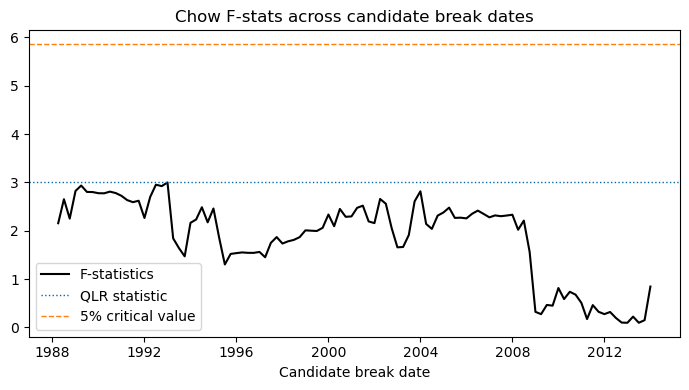

In [11]:
# QLR test
sample = X_adl.dropna().index
trim = 0.15
i_lo = int(np.ceil(trim * len(sample)))
i_hi = int(np.floor((1 - trim) * len(sample)))
break_dates = sample[i_lo:i_hi] # central 70% of sample

f_stats = pd.Series(index=break_dates, dtype=float)
for t in break_dates:
    _, f_test = chow_test(t)
    f_stats[t] = f_test.statistic

# Plot
qlr_cv = 5.86 # Stock & Watson textbook, Table 15.5
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(f_stats.index, f_stats.values, color='black', label='F-statistics')
ax.axhline(f_stats.max(), color='C0', linestyle=':', linewidth=1, label='QLR statistic')
ax.axhline(qlr_cv, color='C1', linestyle='--', linewidth=1, label='5% critical value')
ax.set_xlabel('Candidate break date')
ax.set_title('Chow F-stats across candidate break dates')
ax.legend()
plt.tight_layout()
fig.savefig('output/qlr.eps')
plt.show()